# Crypto Portfolio Risk Analysis

**The question:** A fund manager is deciding whether to hold a mix of 5 coins or just hold Bitcoin. Does spreading money across 5 coins actually lower risk, and by how much?

## Step 1: Get the data

**Which coins?** Bitcoin (BTC), Ethereum (ETH), Solana (SOL), Chainlink (LINK), and Avalanche (AVAX). They are large, easy to trade, and do different jobs: a store of value, two smart-contract platforms of different ages, and a data network. That gives diversification its best chance to work.

**What time period?** January 1, 2023 to October 1, 2026. Starting in 2023 skips the 2022 crash, so risk may look lower than it would over a full market cycle. I'm choosing this period to focus on the current market, and I list it as a limit in the README.

**Source:** daily closing prices from Yahoo Finance, using the `yfinance` package.

In [1]:
import yfinance as yf
import pandas as pd

tickers = ["BTC-USD", "ETH-USD", "SOL-USD", "LINK-USD", "AVAX-USD"]
prices = yf.download(tickers, start="2023-01-01", end="2026-10-01", auto_adjust=True)["Close"]
prices = prices[tickers]          # keep columns in a consistent order
prices.to_csv("../data/prices.csv")
prices.tail()

[                       0%                       ]

[                       0%                       ]

[**********************80%*************          ]  4 of 5 completed

[*********************100%***********************]  5 of 5 completed

Ticker,BTC-USD,ETH-USD,SOL-USD,LINK-USD,AVAX-USD
Date,,,,,
2026-09-26,84406.453125,2695.213135,121.425644,14.154918,10.859573
2026-09-27,84458.085938,2686.926758,122.058701,14.037887,10.911216
2026-09-28,83502.609375,2688.668701,118.836731,15.442647,10.593069
2026-09-29,83622.429688,2676.722168,119.055466,14.597478,11.435551
2026-09-30,83553.851562,2683.679443,117.994812,14.358115,10.933303


## Step 2: Check the data

Before using the data, I check three things: Is anything missing? Does anything look impossible? Does it match what I know about the real world?

### Missing values and date coverage
Count empty prices per coin, and make sure every calendar day is there exactly once (crypto trades 7 days a week, so there should be no gaps).

In [2]:
print("Missing values per coin:")
print(prices.isna().sum())

all_days = pd.date_range(prices.index.min(), prices.index.max(), freq="D")
print(f"\nDate range: {prices.index.min().date()} to {prices.index.max().date()} ({len(prices)} rows)")
print(f"Calendar days with no row: {len(all_days.difference(prices.index))}")
print(f"Duplicate dates: {prices.index.duplicated().sum()}")

Missing values per coin:
Ticker
BTC-USD     0
ETH-USD     0
SOL-USD     0
LINK-USD    0
AVAX-USD    0
dtype: int64

Date range: 2023-01-01 to 2026-09-30 (1369 rows)
Calendar days with no row: 0
Duplicate dates: 0


### Impossible values
Prices must be positive. `describe()` shows the min, max and average for each coin, so anything absurd stands out.

In [3]:
print(f"Prices at or below zero: {(prices <= 0).sum().sum()}")
prices.describe().round(2)

Prices at or below zero: 0


Ticker,BTC-USD,ETH-USD,SOL-USD,LINK-USD,AVAX-USD
count,1369.00,1369.00,1369.00,1369.00,1369.00
mean,67004.22,2550.13,112.78,12.84,21.30
std,28911.67,793.57,64.71,5.13,11.53
min,16625.08,1200.96,9.98,5.12,5.91
25%,41262.06,1871.28,64.96,8.29,11.84
50%,66931.10,2405.79,122.79,12.62,19.16
75%,90513.10,3125.20,159.93,15.65,27.60
max,124752.53,4831.35,261.87,29.29,60.69


### Reality check
When did each coin hit its lowest and highest price? These dates should match real market events.

In [4]:
extremes = pd.DataFrame({
    "Low date": prices.idxmin().dt.date,
    "Low": prices.min().round(2),
    "High date": prices.idxmax().dt.date,
    "High": prices.max().round(2),
})
extremes

,Low date,Low,High date,High
Ticker,,,,
BTC-USD,2023-01-01,16625.08,2025-10-06,124752.53
ETH-USD,2023-01-01,1200.96,2025-08-22,4831.35
SOL-USD,2023-01-01,9.98,2025-01-18,261.87
LINK-USD,2023-06-19,5.12,2024-12-12,29.29
AVAX-USD,2026-06-19,5.91,2024-03-18,60.69


### Data checks

- **Missing values:** none for any coin. Every calendar day from Jan 1, 2023 to Sep 30, 2026 is present exactly once (1,369 rows), so no rows were dropped.
- **Impossible values:** no prices at or below zero.
- **Reality check:** the prices match known market history.
  - BTC's low of \$16.6k on Jan 1, 2023 is the bottom after the FTX collapse in November 2022.
  - BTC's highest close, \$124.8k on Oct 6, 2025, matches its all-time high.
  - ETH peaked at \$4.8k in August 2025.
  - SOL peaked at \$262 in January 2025.
  - AVAX peaked at \$61 in March 2024.
- **Note for later:** the period starts at a market bottom, so total returns will look very large (BTC rose about 5x). I'll focus on risk measures, and this goes in the Limits section.

## Step 3: Explore the data and build the portfolio

### Hypothesis (written before seeing any results)

**I expect the 5-coin portfolio to be slightly *more* risky than holding Bitcoin alone.**

My reasoning has two parts:

1. **The coins move together.** Most cryptocurrencies follow Bitcoin's lead, falling when it trends down and rising when it trends up. If the coins rise and fall at the same time, holding several of them won't offset losses the way diversification normally does.
2. **The smaller coins swing harder.** Ethereum, Solana, Chainlink and Avalanche are smaller and more speculative than Bitcoin, so their price moves tend to be larger. Adding them to the portfolio mixes in more volatility without much diversification benefit to balance it out.

If I'm right, the portfolio will show higher volatility and a deeper maximum drawdown than Bitcoin. If I'm wrong, it will be because the coins are less correlated than I assume.

### Daily returns
Prices can't be compared across coins (BTC is \$80k, LINK is \$15), so I convert them to daily percentage changes. `std` is the typical size of a daily move.

In [5]:
returns = prices.pct_change().dropna()
returns.describe().round(4)

Ticker,BTC-USD,ETH-USD,SOL-USD,LINK-USD,AVAX-USD
count,1368.0000,1368.0000,1368.0000,1368.0000,1368.0000
mean,0.0015,0.0011,0.0028,0.0016,0.0010
std,0.0244,0.0331,0.0445,0.0430,0.0455
min,-0.1413,-0.1501,-0.2043,-0.2116,-0.2695
25%,-0.0108,-0.0146,-0.0241,-0.0234,-0.0248
50%,0.0000,0.0005,-0.0005,-0.0000,-0.0006
75%,0.0126,0.0152,0.0253,0.0237,0.0229
max,0.1252,0.2180,0.3259,0.3283,0.2500


### Extreme single-day moves
The biggest up and down day for each coin. Any move above 50% would point to a data error worth checking in the news.

In [6]:
extreme_moves = pd.DataFrame({
    "Biggest gain": returns.max(),
    "Date of gain": returns.idxmax().dt.date,
    "Biggest loss": returns.min(),
    "Date of loss": returns.idxmin().dt.date,
})
extreme_moves.style.format({"Biggest gain": "{:.1%}", "Biggest loss": "{:.1%}"})

,Biggest gain,Date of gain,Biggest loss,Date of loss
Ticker,,,,
BTC-USD,12.5%,2026-02-06,-14.1%,2026-02-05
ETH-USD,21.8%,2025-05-08,-15.0%,2026-02-05
SOL-USD,32.6%,2023-01-14,-20.4%,2025-03-03
LINK-USD,32.8%,2024-12-02,-21.2%,2025-10-10
AVAX-USD,25.0%,2023-01-11,-27.0%,2025-10-10


**Extreme moves check:** the largest single-day move was +32.8% (LINK, Dec 2, 2024), so nothing reached 50%. The big days line up with real events:
- **Oct 10, 2025:** AVAX fell 27% and LINK fell 21% during the record crypto liquidation selloff, when about \$19B in leveraged positions were forced closed.
- **Mar 3, 2025:** SOL fell 20%, ETH 15% and LINK 17% as the jump that followed the announcement of a U.S. strategic crypto reserve reversed.
- **May 8, 2025:** ETH rose 22% after Ethereum's Pectra upgrade.
- **Feb 5–6, 2026:** BTC fell 14% and then rose 12.5% the next day. Both days move together across all coins, so they look like a real market event rather than a data error.

I treat all of these as real and keep them in the data.

The daily standard deviation shows the pattern behind my hypothesis: BTC moves about 2.4% on a typical day, ETH 3.3%, and SOL, LINK and AVAX about 4.3–4.6%.

### Growth of \$100 in each coin
Starting every coin at 100 puts them on the same scale. I use a log scale so that a 10x gain in SOL doesn't flatten the other lines; on a log scale, equal distances mean equal percentage changes.

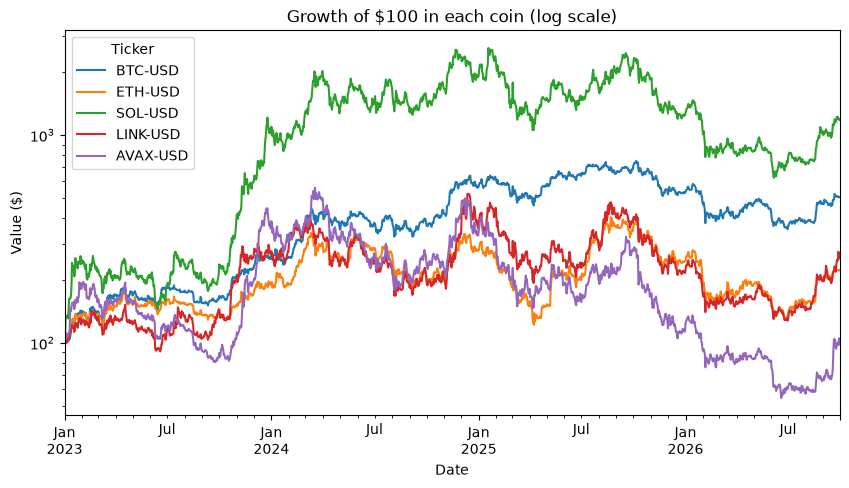

In [7]:
import matplotlib.pyplot as plt

ax = (prices / prices.iloc[0] * 100).plot(figsize=(10, 5), logy=True,
                                          title="Growth of $100 in each coin (log scale)")
ax.set_ylabel("Value ($)")
plt.show()

### Build the portfolio

**Weights:** BTC 40%, ETH 30%, SOL 15%, LINK 10%, AVAX 5%. Bigger, more established coins get bigger weights, roughly following their market size. The smaller coins add diversification without dominating the risk.

**Bitcoin benchmark:** \$10,000 held only in Bitcoin. Without it, the portfolio's numbers have nothing to be compared against.

**Note:** this math rebalances back to the target weights every day, which real portfolios don't do. That goes in the Limits section.

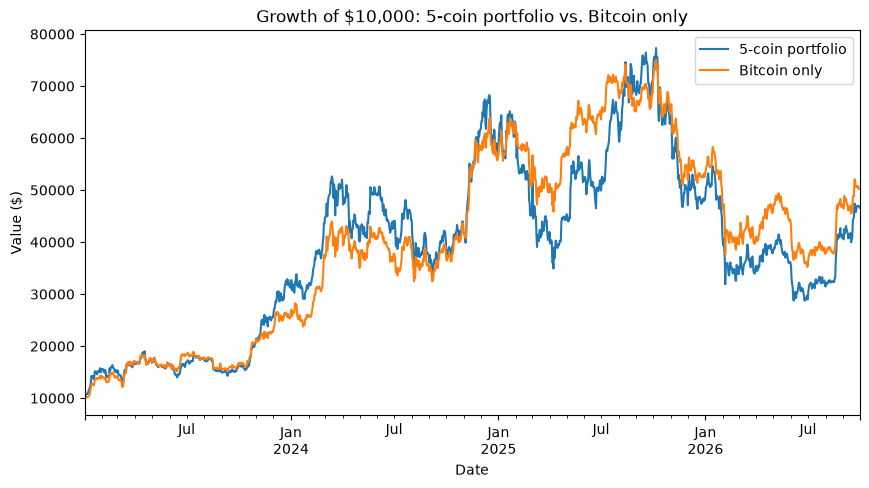

In [8]:
weights = pd.Series({"BTC-USD": 0.40, "ETH-USD": 0.30, "SOL-USD": 0.15,
                     "LINK-USD": 0.10, "AVAX-USD": 0.05})
port = (returns * weights).sum(axis=1)
value = 10000 * (1 + port).cumprod()
btc_value = 10000 * (1 + returns["BTC-USD"]).cumprod()

ax = pd.DataFrame({"5-coin portfolio": value, "Bitcoin only": btc_value}).plot(
    figsize=(10, 5), title="Growth of $10,000: 5-coin portfolio vs. Bitcoin only")
ax.set_ylabel("Value ($)")
plt.show()

## Step 4: Calculate the risk numbers

Every number is calculated twice, once for the portfolio and once for Bitcoin alone, so each one has something to be compared against. The four measures:

- **Total return:** how much \$10,000 grew over the whole period.
- **Yearly volatility:** how much returns swing around, scaled to a year (crypto trades 365 days a year, so I multiply by √365).
- **Max drawdown:** the worst drop from a peak to a later low. It shows the most pain an investor would have felt.
- **95% daily VaR (Value at Risk):** on 95% of days, the loss was smaller than this. The other 1 in 20 days were worse.

In [9]:
import numpy as np

def risk_summary(daily_returns, value):
    return {
        "Total return": value.iloc[-1] / 10000 - 1,
        "Yearly volatility": daily_returns.std() * np.sqrt(365),
        "Max drawdown": (value / value.cummax() - 1).min(),
        "95% daily VaR": daily_returns.quantile(0.05),
    }

summary = pd.DataFrame({
    "Portfolio": risk_summary(port, value),
    "Bitcoin only": risk_summary(returns["BTC-USD"], btc_value),
})
summary["Difference"] = summary["Portfolio"] - summary["Bitcoin only"]
summary.style.format("{:.1%}")

,Portfolio,Bitcoin only,Difference
Total return,366.5%,402.6%,-36.0%
Yearly volatility,56.2%,46.6%,9.6%
Max drawdown,-62.8%,-53.1%,-9.8%
95% daily VaR,-4.4%,-3.6%,-0.9%


### Risk of each coin on its own
The same measures for each coin held by itself. This shows where the portfolio's extra risk comes from.

In [10]:
coin_risk = pd.DataFrame({
    coin: risk_summary(returns[coin], 10000 * (1 + returns[coin]).cumprod())
    for coin in returns.columns
}).T
coin_risk.style.format("{:.1%}")

,Total return,Yearly volatility,Max drawdown,95% daily VaR
BTC-USD,402.6%,46.6%,-53.1%,-3.6%
ETH-USD,123.5%,63.2%,-67.6%,-4.8%
SOL-USD,1082.1%,85.1%,-76.3%,-6.1%
LINK-USD,155.4%,82.1%,-75.5%,-6.1%
AVAX-USD,0.6%,87.0%,-90.3%,-6.6%


### Correlation between coins
Correlation measures how closely two coins move together: 1 means they move in lockstep, 0 means they are unrelated. Diversification only lowers risk when assets don't move together.

In [11]:
corr = returns.corr()
avg_corr = corr.values[np.triu_indices(len(corr), k=1)].mean()
print(f"Average correlation between coin pairs: {avg_corr:.2f}")
corr.round(2)

Average correlation between coin pairs: 0.72


Ticker,BTC-USD,ETH-USD,SOL-USD,LINK-USD,AVAX-USD
Ticker,,,,,
BTC-USD,1.00,0.82,0.73,0.67,0.68
ETH-USD,0.82,1.00,0.71,0.75,0.70
SOL-USD,0.73,0.71,1.00,0.66,0.71
LINK-USD,0.67,0.75,0.66,1.00,0.73
AVAX-USD,0.68,0.70,0.71,0.73,1.00


### Did diversification do anything at all?
If the coins moved in perfect lockstep, the portfolio's volatility would equal the weighted average of each coin's volatility. Any gap between the two is the benefit of diversification.

In [12]:
coin_vol = returns.std() * np.sqrt(365)
weighted_avg_vol = (coin_vol * weights).sum()
port_vol = port.std() * np.sqrt(365)
print(f"Weighted average of coin volatilities: {weighted_avg_vol:.1%}")
print(f"Actual portfolio volatility:           {port_vol:.1%}")
print(f"Reduction from diversification:        {weighted_avg_vol - port_vol:.1%} points")
print(f"Bitcoin alone:                         {coin_vol['BTC-USD']:.1%}")

Weighted average of coin volatilities: 63.0%
Actual portfolio volatility:           56.2%
Reduction from diversification:        6.8% points
Bitcoin alone:                         46.6%


## Findings

**Spreading money across 5 coins made the portfolio *more* risky than holding Bitcoin alone, not less.** From Jan 2023 to Sep 2026, the portfolio's yearly volatility was 56.2% vs. 46.6% for Bitcoin (9.6 points higher). Its max drawdown was −62.8% vs. −53.1%, and it earned less: +367% vs. +403%.

**My hypothesis was correct.** Both of my reasons hold up in the data:

1. **The coins move together.** The average correlation between coin pairs is 0.72, and BTC and ETH are at 0.82. When Bitcoin falls, the others fall with it.
2. **The smaller coins swing harder.** Every other coin was more volatile than Bitcoin (ETH 63%; SOL, LINK and AVAX 82–87%), and each had a deeper drawdown. AVAX fell 90% from its peak.

**One nuance:** diversification still did *something*. The portfolio's volatility (56.2%) is about 7 points lower than the weighted average of its coins (63.0%), because the coins don't move in perfect lockstep. That benefit just wasn't big enough to make up for adding coins that are much riskier than Bitcoin.

**For the fund manager:** in this period, adding these four coins brought more risk and less return. Diversifying *within* crypto doesn't make a portfolio safer than Bitcoin alone.